# Problem set 5

### Problem 1: Renewal problem

Consider a sequence of random variables $X_i$, each (continuous) uniformly distributed between 0 and 1. Let $N$ represent the first instance where the cumulative sum of the $X_i$'s exceeds 1.0. Specifically, $N$ is defined such that $X_1+ \dots + X_{N−1}<1$ and $X_1+\dots +X_N>1$.

The value of $N$ can be determined using a simulation: iteratively draw values from the uniform distribution and accumulate them until the total surpasses 1. Since $N$ depends on the random draws $N_i$, it is itself a random variable with its own distribution.

To estimate the expected value of $N$, we can perform the simulation repeatedly, say `REP` times, generating values $N_1$, $N_2$, …, $N_{\text{REP}}$. By the law of large numbers, the sample average of these $N_i$ values, i.e. $(N_1+…+N_\text{REP})/\text{REP}$ will converge to the expected value of $N$ as `REP` becomes large. For this problem, consider `REP=10**6`.

Write a function `random_math()`, which takes no parameters, that determines the average number of random numbers uniformly distributed between 0 and 1 that need to be generated for the sum of those numbers to be greater than 1.00. The output on the screen (4 decimals precise) should look like this:

    The average amount of numbers generated (based on 1 million trials) is x.xxxx

Do you perhaps recognize the outcome?

In [23]:
# Your solution goes here
import random
def random_math(): 
    rep = 10**6
    N = 0 
    Nsum = 0
    for _ in range(rep): 
        if N < 1: 
            N += random.random()
        else: 
            Nsum += N
            N = 0
    return round(Nsum/rep, 4)
print(f"The average amount of numbers generated (based on 1 millioin trials) is {random_math()}")
        


The average amount of numbers generated (based on 1 millioin trials) is 0.3654


### Problem 2: Average distance

Write a function `square(n)` that estimates the average Euclidean distance between two random points within a unit square (1x1). The function takes one parameter`n` which specifies the number of iterations (or random point pairs to consider). This is a classic example of a clear and apparently simple problem, which is difficult to analytically solve. (Give it a try, then you'll soon find yourself quite stuck. Think back to this problem after Probability Theory and Statistics 2.). Do at least try to make an estimation, so you can assess whether the answer of your program is somewhat realistic.

<center><img src="https://i.ibb.co/3dhmtMk/square.png" border="0"></center>

In [50]:
# Your solution goes here
import math
def square(n):
    total = 0

    for _ in range(n):
        x1 = random.random()
        y1 = random.random()

        x2 = random.random()
        y2 = random.random()

        d = math.sqrt((x2-x1)**2 + (y2-y1)**2)

        total += d

    return total / n
print(square(1000000))

0.5214063378716112


### Problem 3: Taylor approximations

The $N$th order Taylor polynomial of $f(x) = \cos(x)$ is given by
$$T_N(x) = \sum_{n=0}^{N} (-1)^n \frac{x^{2n}}{(2n)!}.$$
Plot the graphs of $\cos(x)$ and its Taylor approximations $T_1(x)$, $T_2(x)$ and $T_3(x)$ in the points $x \in \{-4.0, -3.95, \dots, 3.95, 4.0\}$. Your plot should look something like this:

<center><img src="https://i.ibb.co/T2xXqHP/matplotlib-taylor.png" width = 500 border="0"></center>

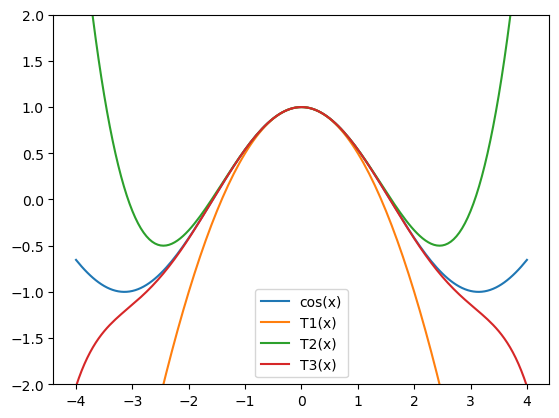

In [4]:
# Your solution goes here
import math
import matplotlib.pyplot as plt
def taylor(n, x): 
    sum = 0
    for i in range(n+1): 
        t = ((-1)**i) * (x**(2*i))/math.factorial(2*i)
        sum += t
    return sum

x = []
y1 = []
y2 = []
y3 = []
cosine = []

n = 1
xval = -4
for _ in range(161):
    x.append(xval)
    y1.append(taylor(n, xval))
    y2.append(taylor(n+1, xval))
    y3.append(taylor(n+2, xval))
    cosine.append(math.cos(xval))
    xval += 0.05
plt.plot(x, cosine)
plt.plot(x, y1)
plt.plot(x, y2)
plt.plot(x, y3)
plt.legend(["cos(x)", "T1(x)", "T2(x)", "T3(x)"])
plt.ylim(-2, 2)
plt.show()



### Problem 4: Sierpinksi triangle

Assume you have three points at the corner of an equilaterial triangle: $P_1 = (0, 0)$, $P_2 = (0.5,\frac{\sqrt{2}}{2})$ and $P_3 = (1, 0)$. Now you want to generate another set of points $p_i = (x_i, y_i)$ such that $p_1 = (0, 0)$ and $p_{i+1}$ is the midpoint between $p_i$ and $P_1$ with 33% probability, the midpoint between $p_i$ and $P_2$ with 33% probability and the midpoint between $p_i$ and $P_3$ with 33% probability. 

Write a function `sierpinski(n)` that generates the points $p_i$ for $i=1, \dots, n$. The function should make a plot of the points using blue dots. 

Use `plt.axis("equal")` to make the plot look nicer. 

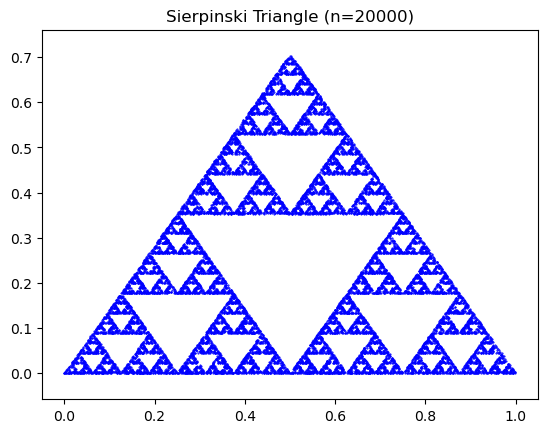

In [6]:
# Your solution goes here
import random
import matplotlib.pyplot as plt
import math

def sierpinski(n: int):
    # Triangle corners
    P1 = (0.0, 0.0)
    P2 = (0.5, math.sqrt(2) / 2)
    P3 = (1.0, 0.0)
    corners = [P1, P2, P3]

    # Start point p1
    x, y = P1

    xs = [x]
    ys = [y]

    # Generate points p2 ... pn
    for _ in range(n - 1):
        cx, cy = random.choice(corners)   # pick a corner with equal probability
        x = (x + cx) / 2                  # midpoint x
        y = (y + cy) / 2                  # midpoint y
        xs.append(x)
        ys.append(y)

    # Plot
    plt.plot(xs, ys, "b.", markersize=1)  # blue dots
    plt.axis("equal")
    plt.title(f"Sierpinski Triangle (n={n})")
    plt.show()

# Example:
sierpinski(20000)


### Problem 5: Binary numbers

#### Part 1 - Binary to decimal

Write a function `binaryToDecimal(n)` that converts a binary number into its decimal equivalent. The function takes an integer as input. In order to easily access the individual bits of the decimal number, it might be helpful to convert the integer into a string using the `str` function, and then use indexing to determine the individual values. Alternatively one can use the modulo operator to find the respective digits.

Recall what a binary number represents:

$$(10011011)_2 = 1 \cdot 2^7 + 0 \cdot 2^6 + 0 \cdot 2^5 + 1 \cdot 2^4 + 1 \cdot 2^3 + 0 \cdot 2^2 + 1 \cdot 2^1 + 1 \cdot 2^0 = (155)_{10}.$$

Expected behaviour:

```python
print(binaryToDecimal(10011011))
```
---
    155

In [21]:
# Your solution goes here
def BinToDec(n): 
    temp = str(n)
    reverse_number = temp[::-1]
    p = 0
    sum = 0
    for i in range(len(reverse_number)):
        sum += int(reverse_number[i]) * 2**p
        p +=1
    return sum
BinToDec(10011011)

155

#### Part 2 - Decimal to binary I

Write a function `decimalToBinary(n)` that converts a decimal number into its binary equivalent. The function takes a nonnegative integer as input. 

Hint: Depending on your approach, it may help to first think about what the length of the resulting binary number will be.

Expected behaviour:

```python
print(decimalToBinary(625))
```
---
    1001110001

In [ ]:
# Your solution goes here
# Your solution goes here
def decimalToBinary(n):
    if n == 0:
        return 0

    p = -1
    # find the largest power of 2 <= n
    while 2**(p + 1) <= n:
        p += 1

    current = 2**p
    binary = ""

    while p >= 0:
        if n - current >= 0:
            binary += "1"
            n -= current
        else:
            binary += "0"

        p -= 1
        if p >= 0:
            current = 2**p

    return int(binary)

print(decimalToBinary(625))



1001110001


#### Part 3 - Decimal to binary II

In the lecture notes two different algorithms were presented to convert a decimal integer into binary. Implement the other algorithm to the the one you used in part 2.

In [12]:
# Your solution goes here
def dectobin(n):
    number = 0 
    bin = ""
    while n > 0: 
        if n % 2 == 1: 
            number = n//2
            n = number
            bin+= "1"
        elif n % 2 == 0: 
            number = n/2
            n = number
            bin+="0"
    return int(bin[::-1])
dectobin(625)

1001110001